In [1]:
# load the numerical dataset
import pandas as pd
df_num = pd.read_csv("/kaggle/input/datasets/geetr02/datasset/german.data-numeric", sep=r'\s+', header=None)
df_num.head()



,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
0,1,6,4,12,5,5,3,4,1,67,...,0,0,1,0,0,1,0,0,1,1
1,2,48,2,60,1,3,2,2,1,22,...,0,0,1,0,0,1,0,0,1,2
2,4,12,4,21,1,4,3,3,1,49,...,0,0,1,0,0,1,0,1,0,1
3,1,42,2,79,1,4,3,4,2,45,...,0,0,0,0,0,0,0,0,1,1
4,1,24,3,49,1,3,3,4,4,53,...,1,0,1,0,0,0,0,0,1,2


In [2]:
# Load the original dataset
df_org = pd.read_csv("/kaggle/input/datasets/geetr02/datasset/german.data", sep=r'\s+', header=None)
df_org.head()

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


# 1. Data Preprocessing

In [3]:


# Convert target variable to binary format (0=low risk, 1=high risk)
df_org['credit_risk'] = df_org[20].map({1:0, 2:1})

# drop the original column
df_org.drop(20, axis=1, inplace=True)


# Display the updated dataframe
df_org.head()

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


## 1.1 Column Renaming

In [4]:

# Renaming the columns
df_org = df_org.rename(columns = {
  0:  "Status of existing checking account",
  1: "Duration in month",
  2: "Credit History",
  3: "Purpose",
  4: "Credit amount",
  5: "Savings account/bonds",
  6: "Present employment since",
  7: "Installment rate in percentage of disposable income",
  8: "Personal status and sex",
  9: "Other debtors /guarantors",
  10: "Present residence since",
  11: "Property",
  12: "Age in years",
  13: "Other installment plans",
  14: "Housing",
  15: "Number of existing credits at this bank",
  16: "Job",
  17: "Number of people being liable to provide maintenance for",
  18: "Telephone",
  19: "Foreign worker"


})

print(df_org.columns)


df_new = df_org.copy()

Index(['Status of existing checking account', 'Duration in month',
       'Credit History', 'Purpose', 'Credit amount', 'Savings account/bonds',
       'Present employment since',
       'Installment rate in percentage of disposable income',
       'Personal status and sex', 'Other debtors /guarantors',
       'Present residence since', 'Property', 'Age in years',
       'Other installment plans', 'Housing',
       'Number of existing credits at this bank', 'Job',
       'Number of people being liable to provide maintenance for', 'Telephone',
       'Foreign worker', 'credit_risk'],
      dtype='object')


## 1.2 One hot encoding the categorical values

In [5]:
# One hot encoding
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

cat_cols = df_new.select_dtypes(include=['object']).columns

encoder = OneHotEncoder(sparse_output=False)

encoded_data = encoder.fit_transform(df_new[cat_cols])

encoded_df = pd.DataFrame(
    encoded_data,
    columns = encoder.get_feature_names_out(cat_cols)
)

final_df = pd.concat(
    [df_new.drop(columns=cat_cols), encoded_df],
    axis=1
)

print("\nOne-Hot Encoded Data:")
final_df.head()





One-Hot Encoded Data:


,Duration in month,Credit amount,Installment rate in percentage of disposable income,Present residence since,Age in years,Number of existing credits at this bank,Number of people being liable to provide maintenance for,credit_risk,Status of existing checking account_A11,Status of existing checking account_A12,...,Housing_A152,Housing_A153,Job_A171,Job_A172,Job_A173,Job_A174,Telephone_A191,Telephone_A192,Foreign worker_A201,Foreign worker_A202
0,6,1169,4,4,67,2,1,0,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
1,48,5951,2,2,22,1,1,1,0.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2,12,2096,2,3,49,1,2,0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
3,42,7882,2,4,45,1,2,0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
4,24,4870,3,4,53,2,2,1,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


In [6]:
print(final_df.shape)

(1000, 62)


In [7]:
print(final_df.columns.tolist())

['Duration in month', 'Credit amount', 'Installment rate in percentage of disposable income', 'Present residence since', 'Age in years', 'Number of existing credits at this bank', 'Number of people being liable to provide maintenance for', 'credit_risk', 'Status of existing checking account_A11', 'Status of existing checking account_A12', 'Status of existing checking account_A13', 'Status of existing checking account_A14', 'Credit History_A30', 'Credit History_A31', 'Credit History_A32', 'Credit History_A33', 'Credit History_A34', 'Purpose_A40', 'Purpose_A41', 'Purpose_A410', 'Purpose_A42', 'Purpose_A43', 'Purpose_A44', 'Purpose_A45', 'Purpose_A46', 'Purpose_A48', 'Purpose_A49', 'Savings account/bonds_A61', 'Savings account/bonds_A62', 'Savings account/bonds_A63', 'Savings account/bonds_A64', 'Savings account/bonds_A65', 'Present employment since_A71', 'Present employment since_A72', 'Present employment since_A73', 'Present employment since_A74', 'Present employment since_A75', 'Person

In [8]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 62 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Duration in month                                         1000 non-null   int64  
 1   Credit amount                                             1000 non-null   int64  
 2   Installment rate in percentage of disposable income       1000 non-null   int64  
 3   Present residence since                                   1000 non-null   int64  
 4   Age in years                                              1000 non-null   int64  
 5   Number of existing credits at this bank                   1000 non-null   int64  
 6   Number of people being liable to provide maintenance for  1000 non-null   int64  
 7   credit_risk                                               1000 non-null   int64  
 8   Status of existing 

In [9]:
rename_dict = {

# Status of existing checking account
'Status of existing checking account_A11': 'checking_balance_negative',
'Status of existing checking account_A12': 'checking_balance_0_200DM',
'Status of existing checking account_A13': 'checking_balance_ge_200DM',
'Status of existing checking account_A14': 'no_checking_account',


# Credit History
'Credit History_A30': 'credit_all_paid',
'Credit History_A31': 'credit_all_paid_bank',
'Credit History_A32': 'credit_paid_current',
'Credit History_A33': 'credit_past_delay',
'Credit History_A34': 'credit_critical_account',

# Purpose
'Purpose_A40': 'purpose_car(new)',
'Purpose_A41': 'purpose_car(old)',
'Purpose_A42': 'purpose_furniture',
'Purpose_A43': 'purpose_radio/tv',
'Purpose_A44': 'purpose_domestic_appliances',
'Purpose_A45': 'purpose_repairs',
'Purpose_A46': 'purpose_education',
'Purpose_A47': 'purpose_vacation',
'Purpose_A48': 'purpose_retraining',
'Purpose_A49': 'purpose_business',
'Purpose_A410': 'purpose_others',


# Savings account/bonds
'Savings account/bonds_A61': 'savings_balance_lt_100DM',
'Savings account/bonds_A62': 'savings_balance_100_to_500DM',
'Savings account/bonds_A63': 'savings_balance_500_to_1000DM',
'Savings account/bonds_A64': 'savings_balance_ge_1000DM',
'Savings account/bonds_A65': 'no_or_unknown_savings',

# Present employment since
'Present employment since_A71': 'employment_duration_unemployed',
'Present employment since_A72': 'employment_duration_lt_1yr',
'Present employment since_A73': 'employment_duration_1_to_4yrs',
'Present employment since_A74': 'employment_duration_4_to_7yrs',
'Present employment since_A75': 'employment_duration_gte_7yrs',

# Personal status and sex
'Personal status and sex_A91': 'male_divorced_separated',
'Personal status and sex_A92': 'female_divorced_separated_married',
'Personal status and sex_A93': 'male_single',
'Personal status and sex_A94': 'male_married_widowed',
'Personal status and sex_A95': 'female_single',

# Other debtors/guarantors
'Other debtors /guarantors_A101': 'guarantors_none',
'Other debtors /guarantors_A102': 'guarantors_co-applicant',
'Other debtors /guarantors_A103': 'guarantors_guarantor',

# Property
'Property_A121': 'property_real_estate',
'Property_A122': 'property_building_savings_life_insurance',
'Property_A123': 'property_car_or_other',
'Property_A124': 'property_unknown_or_none',

 # Other installment plans
 'Other installment plans_A141': 'installment_plan_bank',
 'Other installment plans_A142': 'installment_plan_store',
 'Other installment plans_A143': 'no_installment_plan',

 # Housing
 'Housing_A151': 'housing_rent',
 'Housing_A152': 'housing_own',
 'Housing_A153': 'housing_free',

 # Job
 'Job_A171': 'job_unemployed_unskilled_nonresident',
 'Job_A172': 'job_unskilled_resident',
 'Job_A173': 'job_skilled_employee',
 'Job_A174': 'job_management_self_employed_highly_qualified',

 # Telephone
 'Telephone_A191': 'telephone_none',
 'Telephone_A192': 'telephone_registered',

 # Foreign worker
 'Foreign worker_A201': 'foreign_worker_yes',
 'Foreign worker_A202': 'foreign_worker_no'

}

df_readable = final_df.rename(columns=rename_dict)
df_readable.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 62 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Duration in month                                         1000 non-null   int64  
 1   Credit amount                                             1000 non-null   int64  
 2   Installment rate in percentage of disposable income       1000 non-null   int64  
 3   Present residence since                                   1000 non-null   int64  
 4   Age in years                                              1000 non-null   int64  
 5   Number of existing credits at this bank                   1000 non-null   int64  
 6   Number of people being liable to provide maintenance for  1000 non-null   int64  
 7   credit_risk                                               1000 non-null   int64  
 8   checking_balance_ne

## Separate features and target


In [10]:
df_readable.columns

Index(['Duration in month', 'Credit amount',
       'Installment rate in percentage of disposable income',
       'Present residence since', 'Age in years',
       'Number of existing credits at this bank',
       'Number of people being liable to provide maintenance for',
       'credit_risk', 'checking_balance_negative', 'checking_balance_0_200DM',
       'checking_balance_ge_200DM', 'no_checking_account', 'credit_all_paid',
       'credit_all_paid_bank', 'credit_paid_current', 'credit_past_delay',
       'credit_critical_account', 'purpose_car(new)', 'purpose_car(old)',
       'purpose_others', 'purpose_furniture', 'purpose_radio/tv',
       'purpose_domestic_appliances', 'purpose_repairs', 'purpose_education',
       'purpose_retraining', 'purpose_business', 'savings_balance_lt_100DM',
       'savings_balance_100_to_500DM', 'savings_balance_500_to_1000DM',
       'savings_balance_ge_1000DM', 'no_or_unknown_savings',
       'employment_duration_unemployed', 'employment_duration_lt_1

In [11]:
X = df_readable.drop('credit_risk', axis=1)
y=df_readable['credit_risk']

In [12]:
# Check for class imbalance
y.value_counts()

credit_risk
0    700
1    300
Name: count, dtype: int64

In [13]:
y.info()

<class 'pandas.core.series.Series'>
RangeIndex: 1000 entries, 0 to 999
Series name: credit_risk
Non-Null Count  Dtype
--------------  -----
1000 non-null   int64
dtypes: int64(1)
memory usage: 7.9 KB


In [14]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 61 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Duration in month                                         1000 non-null   int64  
 1   Credit amount                                             1000 non-null   int64  
 2   Installment rate in percentage of disposable income       1000 non-null   int64  
 3   Present residence since                                   1000 non-null   int64  
 4   Age in years                                              1000 non-null   int64  
 5   Number of existing credits at this bank                   1000 non-null   int64  
 6   Number of people being liable to provide maintenance for  1000 non-null   int64  
 7   checking_balance_negative                                 1000 non-null   float64
 8   checking_balance_0_

## Train-test split

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Model Development

6.1 Experiment 1: Baseline Models (Original Dataset)

In [16]:
# Linear model
from sklearn.linear_model import LogisticRegression
# Tree models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
# K-Nearest Neighbors
from sklearn.neighbors import KNeighborsClassifier
# Support Vector Machine
from sklearn.svm import SVC
#Naive Bayes
from sklearn.naive_bayes import GaussianNB

# Import metrics
from sklearn.metrics import recall_score, accuracy_score, precision_score, f1_score


algo_list = {
    "log_reg": LogisticRegression(random_state=42, max_iter = 10000),
    "decision_tree": DecisionTreeClassifier(random_state=42),
    "random_forest": RandomForestClassifier(random_state=42),
    "svm_model": SVC(random_state=42),
    "knn": KNeighborsClassifier(),
    "naive_bayes": GaussianNB()
}

results = []

for name, model in algo_list.items():
  model.fit(X_train, y_train)
  pred_val = model.predict(X_test)



  accuracy = accuracy_score(y_test, pred_val)
  recall = recall_score(y_test, pred_val)
  precision = precision_score(y_test, pred_val)
  f1 = f1_score(y_test, pred_val)

  results.append({
      "Model": name,
      "Accuracy": accuracy,
      "Precision": precision,
      "Recall": recall,
      "F1 score": f1
  })







In [17]:
results_df = pd.DataFrame(results)
results_df.set_index("Model", inplace=True)
results_df

,Accuracy,Precision,Recall,F1 score
Model,,,,
log_reg,0.78,0.666667,0.533333,0.592593
decision_tree,0.63,0.379310,0.366667,0.372881
random_forest,0.74,0.605263,0.383333,0.469388
svm_model,0.71,0.583333,0.116667,0.194444
knn,0.68,0.447368,0.283333,0.346939
naive_bayes,0.72,0.527027,0.650000,0.582090


### Insight

Logistic Regression performed better than the other baseline models based on accuracy and F1-score. However, since credit risk prediction involves different consequences for incorrect predictions, other metrics should also be considered. Naive Bayes achieved higher recall, meaning it was able to identify more high-risk applicants, while logistic Regression had higher precision, meaning its high-risk predictions were more reliable. Therefore, the preferred model depends on whether the priority is reducing financial risk or avoiding unnecessary rejection of applicants.  

### 6.2 Experiment - 2 (handling class imbalance with weights)


In [18]:
algo_list = {
    "log_reg": LogisticRegression(random_state=42, class_weight="balanced", max_iter=10000),
    "decision_tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "random_forest": RandomForestClassifier(random_state=42, class_weight="balanced"),
    "svm_model": SVC(random_state=42, class_weight="balanced")

}

results = []

for name, model in algo_list.items():
  model.fit(X_train, y_train)
  pred_val = model.predict(X_test)

  accuracy = accuracy_score(y_test, pred_val)
  recall = recall_score(y_test, pred_val)
  precision = precision_score(y_test, pred_val)
  f1 = f1_score(y_test, pred_val)

  results.append({
      "Model": name,
      "Accuracy": accuracy,
      "Precision": precision,
      "Recall": recall,
      "F1 score": f1
  })

In [19]:
results_df = pd.DataFrame(results)
results_df.set_index("Model", inplace=True)
results_df

,Accuracy,Precision,Recall,F1 score
Model,,,,
log_reg,0.750,0.558140,0.800000,0.657534
decision_tree,0.665,0.440678,0.433333,0.436975
random_forest,0.745,0.628571,0.366667,0.463158
svm_model,0.690,0.476190,0.333333,0.392157


### Insights

**Logistic Regression**: Recall increased substantially (0.512 -> 0.800), while accuracy and precision decreased.


**Decision Tree**: All evaluation metrics improved after applying class weights.


**Random Forest**: Performance remained almost unchanged, indicating minimal impact.


**SVM**: Recall and F1-score improved, but accuracy and precision decreased.

Overall, class weights improved the detection of the minority class for some models, but the improvement often came with a reduction in a precision or accuracy.


### 6.3 Experiment-3 (Hyperparameter Tuning)

In [20]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Define the parameter grid for logistic regression
# I want to test different levels of regularisation 
# and class weighting
logistic_param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "class_weight": [None, "balanced"]
}

# Define the parameter grid for random forest
# I want to test the number of trees and different levels
# of tree complexity
rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 20, None],
    "min_samples_leaf": [1, 2, 5]
}

# Create the logistic Regression model
# max_iter is increased to give the model more iterations to coverage
log_reg = LogisticRegression (
    random_state=42,
    max_iter = 10000, 
    solver="liblinear"
)

# Set up GridSearchCV for logistic Regression
# cv = 5 means combination is evaluated using 5-fold cross-validation
# F1 score  is used because both precision and recall matter for this project.
log_reg_grid = GridSearchCV(
    estimator=log_reg, 
    param_grid=logistic_param_grid,
    cv=5,
    scoring="f1"
)

# Run the hyperparameter search on the training data
# The test set is kept separate and is not used during tuning
log_reg_grid.fit(X_train, y_train)

# Create the Random Forest model
rf = RandomForestClassifier(random_state=42)

# Set up GridSearchCV for Random Forest
rf_grid = GridSearchCV(
    estimator=rf, 
    param_grid=rf_param_grid,
    cv=5,
    scoring="f1"
)

# Run the hyperparameter search on the training data
rf_grid.fit(X_train, y_train)

# Check the best parameter combination found for each model
print("Best Logistic Regression parameters:", log_reg_grid.best_params_)
print("Best Logistic Regression CV F1:", log_reg_grid.best_score_)

print("Best Random Forest parameters:", rf_grid.best_params_)
print("Best Random Forest CV F1:", rf_grid.best_score_)


# Get the best model found during the hyperparameter search
best_log_reg = log_reg_grid.best_estimator_
best_rf = rf_grid.best_estimator_


Best Logistic Regression parameters: {'C': 0.1, 'class_weight': 'balanced'}
Best Logistic Regression CV F1: 0.5886649064131901
Best Random Forest parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}
Best Random Forest CV F1: 0.4960023827832048


In [21]:
# Use the tuned models to make predictions on the test set
# The test set has not been used during hyperparameter tuning
y_pred_log = best_log_reg.predict(X_test)
y_pred_rf = best_rf.predict(X_test)

# Evaluate the tunes logistic Regression on the test set
print("\nTuned Logistic Regression - Test Set")
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log))
print("Recall:", recall_score(y_test, y_pred_log))
print("F1:", f1_score(y_test, y_pred_log))

# Evaluate the tuned Random Forest on the test set
print("\nTuned Random Forest - Test Set")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1:", f1_score(y_test, y_pred_rf))


Tuned Logistic Regression - Test Set
Accuracy: 0.725
Precision: 0.5274725274725275
Recall: 0.8
F1: 0.6357615894039735

Tuned Random Forest - Test Set
Accuracy: 0.76
Precision: 0.6578947368421053
Recall: 0.4166666666666667
F1: 0.5102040816326531


### Observations
- **Logistic Regression**: Hyperparameter tuning resulted in the same test-set F1 score as the 
class-weighted model (0.658), with recall remaining at 0.800.
- **Compared with the baseline**: Logistic Regression's F1 increased from 0.596 to 0.658, mainly due to the large increase in recall (0.517 -> 0.800)
- **Random Forest**: Hyperparameter tuning improved the test-set F1 score slightly from 0.469 to 0.510 and increased precision from 0.605 to 0.658
- The tuned Random Forest still had lower recall (0.417) than the tuned logistic Regression  (0.800), showing a different precison-recall
trade-off.
- Overall, hyperparameter tuning produced a noticeable improvement for Random Forest but did not further improve Logistic Regression's test-set
F1 beyong the class-weighted version.

In [22]:
print(type(y_test))

<class 'pandas.core.series.Series'>


Logistic Regression Confusion Matrix:
[[97 43]
 [12 48]]

Random Forest Confusion Matrix:
[[127  13]
 [ 35  25]]


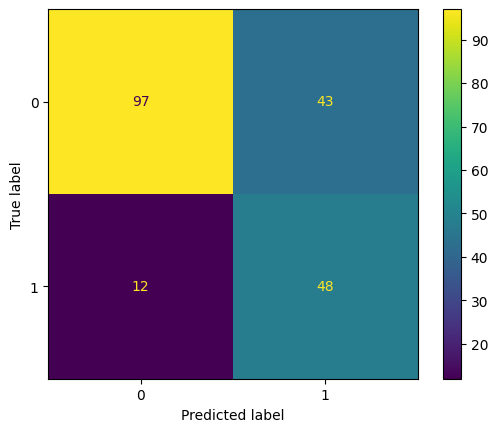

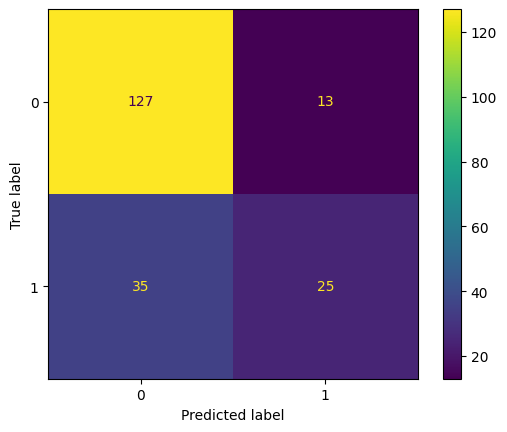

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
# Create a confusion matrix for the tuned Logistic Regression model
cm_log = confusion_matrix(y_test, y_pred_log)

print("Logistic Regression Confusion Matrix:")
print(cm_log)

# Display the confusion matrix as a plot
ConfusionMatrixDisplay(
    confusion_matrix = cm_log
).plot()

# Create a confusion matrix for the tuned Random Forest model
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("\nRandom Forest Confusion Matrix:")
print(cm_rf)

# Display the confusion matrix as a plot
ConfusionMatrixDisplay(
    confusion_matrix=cm_rf
).plot()

### Observation:

Logistic Regression was selected as the final model because it identifies a substantially larger proportion of high-risk applications reducing the number of risky applicants incorrectly classified as low risk. Random Forest performs better at identifying low-risk applicants, with fewer false positives and more true negatices, but it misses many more high-risk applicants. Given the potential cost of approving a high-risk borrower, the higher recall of Logistic Regression was prioritized.

## Fairness analysis

### Gender

In [24]:
import numpy as np
# create a dataframe for the fairness analysis
fairness_df = X_test.copy()

# add the actual and predicted values
fairness_df["actual"] = y_test
fairness_df["predicted"] = y_pred_log

# create a sex column from the one-hot encoded columns
# the only female category is female_divorced_separated_married
fairness_df['sex'] = np.where(
    fairness_df["female_divorced_separated_married"] == 1,
    "female",
    "male"
)

# Create a foreign worker column
fairness_df["foreign_worker"] = np.where(
    fairness_df["foreign_worker_yes"] == 1,
    "yes",
    "no"
)

# check the result 
fairness_df[["actual", "predicted", "sex", "foreign_worker"]].head()

,actual,predicted,sex,foreign_worker
30,0,1,male,yes
128,0,0,male,yes
289,1,1,male,yes
216,0,1,male,yes
966,1,0,male,yes


In [25]:
# First group comparison
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# check model performance for each sex group
for group in ["male", "female"]:
    group_df = fairness_df[fairness_df["sex"] == group]

    print(group)
    print("Accuracy:", accuracy_score(group_df["actual"], group_df["predicted"]))
    print("Precision:", precision_score(group_df["actual"], group_df["predicted"], zero_division=0))
    print("Recall:", recall_score(group_df["actual"], group_df["predicted"], zero_division=0))
    print("F1:", f1_score(group_df["actual"], group_df["predicted"], zero_division=0))
    print()

male
Accuracy: 0.7482014388489209
Precision: 0.543859649122807
Recall: 0.775
F1: 0.6391752577319587

female
Accuracy: 0.6721311475409836
Precision: 0.5
Recall: 0.85
F1: 0.6296296296296297



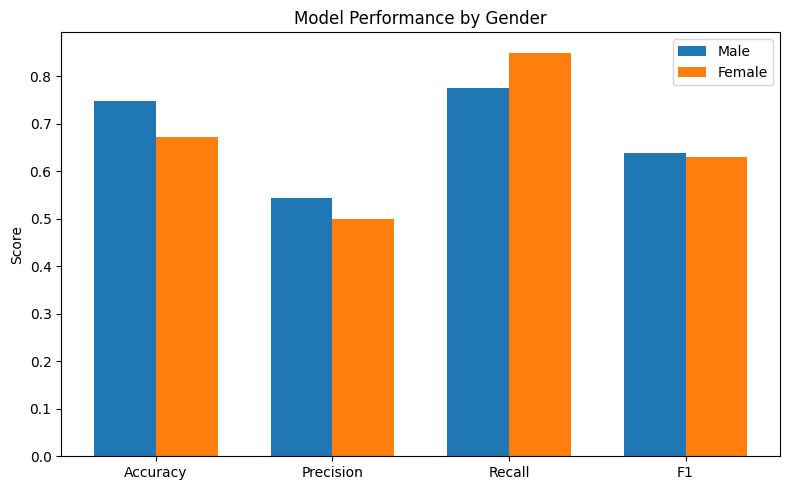

In [26]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Separate applicants by gender
male = fairness_df[fairness_df["sex"] == "male"]
female = fairness_df[fairness_df["sex"] == "female"]

# Calculate performance metrics for each group
def get_metrics(group):
    return [
        accuracy_score(group["actual"], group["predicted"]),
        precision_score(group["actual"], group["predicted"], zero_division=0),
        recall_score(group["actual"], group["predicted"], zero_division=0),
        f1_score(group["actual"], group["predicted"], zero_division=0)
    ]

metrics = ["Accuracy", "Precision", "Recall", "F1"]

male_scores = get_metrics(male)
female_scores = get_metrics(female)

# Plot 
x = np.arange(len(metrics))
width=0.35

plt.figure(figsize=(8, 5))
plt.bar(x-width/2, male_scores, width, label="Male")
plt.bar(x+width/2, female_scores, width, label="Female")

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Model Performance by Gender")
plt.legend()
plt.tight_layout()
plt.show()

#### Observation
The model has similar overall accuracy across male and female applicants, but recall 
is lower for female applicants. This means the model identifies fewer of the actually 
high-risk female applicants than high-risk male applicants.`m

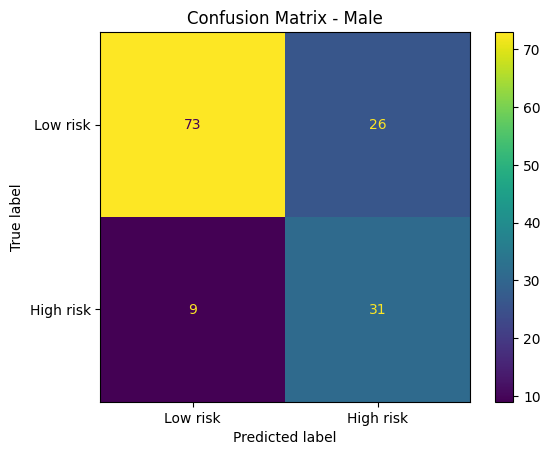

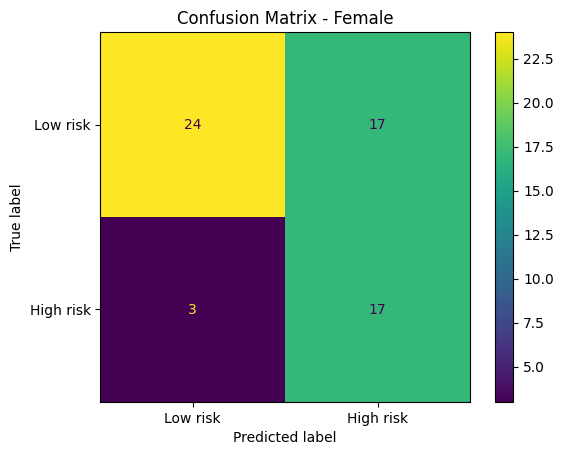

In [27]:
from sklearn.metrics import confusion_matrix

# split the data by gender
male = fairness_df[fairness_df["sex"] == "male"]
female = fairness_df[fairness_df["sex"] == "female"]

# create confusion matrices
cm_male = confusion_matrix(male["actual"], male["predicted"])
cm_female = confusion_matrix(female["actual"], female["predicted"])

# plot male confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_male, 
    display_labels = ["Low risk", "High risk"]
)

disp.plot()
plt.title("Confusion Matrix - Male")
plt.show()

# plot female confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_female, 
    display_labels=["Low risk", "High risk"]
)

disp.plot()
plt.title("Confusion Matrix - Female")
plt.show()

#### Observation
The model has a hiher false-negative rate for female applicants (80%) than male applicants(60%). 
This means the model fails to identify a larger proportion of applicants who are actually high risk 
among females. The recall is therefore lower for females (20%) compared with males (40%). This 
indicates a performance disparity that should be investigated further. 

In [28]:
# get values from each confusion matrix
male_tn, male_fp, male_fn, male_tp = cm_male.ravel()
female_tn, female_fp, female_fn, female_tp = cm_female.ravel()

# calculate fairness error rates
male_tpr = male_tp / (male_tp + male_fn)
male_fnr = male_fn / (male_fn + male_tp)
male_fpr = male_fp / (male_fp + male_tn)

female_tpr = female_tp / (female_tp + female_fn)
female_fnr = female_fn / (female_fn + female_tp)
female_fpr = female_fp / (female_fp + female_tn)

print("Male")
print("TPR / Recall: ", male_tpr)
print("FNR:", male_fnr)
print("FPR:", male_fpr)

print("\nFemale")
print("TPR / Recall:", female_tpr)
print("FNR:", female_fnr)
print("FPR:", female_fpr)

Male
TPR / Recall:  0.775
FNR: 0.225
FPR: 0.26262626262626265

Female
TPR / Recall: 0.85
FNR: 0.15
FPR: 0.4146341463414634


#### Observation

The model is more likely to miss high-risk female applicants than male applicants, 
with an FNR of 80% vs 60%. However, it is also likely to incorrectly flag low-risk 
female applicants (FPR: 7.3% vs 19.2%). This suggests the model is making a different
trade-off in its predictions across gender groups.

## Foreign worker status

In [29]:
# for employment
# y_test = what actually happened
# y_pred = what our model predicted
fairness_df["foreign_worker"] =  np.where(
    fairness_df["foreign_worker_yes"] == 1,
    "yes", 
    "no"
)

fairness_df[["actual", "predicted", "foreign_worker"]].head()

,actual,predicted,foreign_worker
30,0,1,yes
128,0,0,yes
289,1,1,yes
216,0,1,yes
966,1,0,yes


In [30]:
# Split the data into test set
foreign_yes = fairness_df[fairness_df["foreign_worker"] == "yes"]
foreign_no = fairness_df[fairness_df["foreign_worker"] == "no"]

# Check model performance for whether the worker is foreign
for group in ["yes", "no"]:
    group_df = fairness_df[fairness_df["foreign_worker"] == group]
    print(group)
    print("Accuracy:", accuracy_score(group_df["actual"], group_df["predicted"]))
    print("Precision:", precision_score(group_df["actual"], group_df["predicted"], zero_division=0))
    print("Recall:", recall_score(group_df["actual"], group_df["predicted"], zero_division=0))
    print("F1:", f1_score(group_df["actual"], group_df["predicted"], zero_division=0))
    print()

yes
Accuracy: 0.7164948453608248
Precision: 0.5222222222222223
Recall: 0.7966101694915254
F1: 0.6308724832214765

no
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0



In [31]:
print(fairness_df["foreign_worker"].value_counts())

print("\nForeign worker = no")
print(fairness_df[fairness_df["foreign_worker"] == "no"] [["actual", "predicted"]].value_counts())

print("\nForeign worker = yes")
print(fairness_df[fairness_df["foreign_worker"] == "yes"] [["actual", "predicted"]].value_counts())

print(fairness_df.groupby("foreign_worker")["actual"].value_counts())

foreign_worker
yes    194
no       6
Name: count, dtype: int64

Foreign worker = no
actual  predicted
0       0            5
1       1            1
Name: count, dtype: int64

Foreign worker = yes
actual  predicted
0       0            92
1       1            47
0       1            43
1       0            12
Name: count, dtype: int64
foreign_worker  actual
no              0           5
                1           1
yes             0         135
                1          59
Name: count, dtype: int64


#### Observation
The non-foreign worker group has a perfect result, but the sample is extremely small
(n=6), so this result is not reliable enough to treat as evidence of equal or better 
model performance.

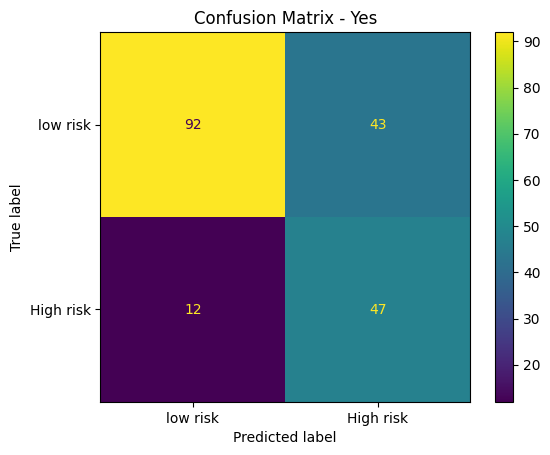

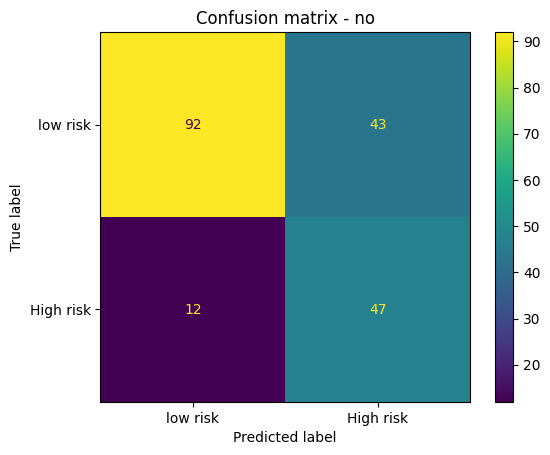

In [32]:
from sklearn.metrics import confusion_matrix

# split the data by foreign worker status
yes = fairness_df[fairness_df["foreign_worker"] == "yes"]
no = fairness_df[fairness_df["foreign_worker"] == "no"]

# Create confusion matrices
cm_yes = confusion_matrix(yes["actual"], yes["predicted"])
cm_no = confusion_matrix(no["actual"], no["predicted"])

# plot yes confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix = cm_yes,
    display_labels = ["low risk", "High risk"]
)

disp.plot()
plt.title("Confusion Matrix - Yes")
plt.show()

# plot no confusion matrix
dis = ConfusionMatrixDisplay(
    confusion_matrix = cm_no,
    display_labels = ["low risk", "high risk"]
)

disp.plot()
plt.title("Confusion matrix - no")
plt.show()

#### Observation
The model performed differently across the two foreign-worker groups. For foreign workers,
the model correctly identified 19 out of 59 high-risk cases, while 40 were incorrectly classify as low risk. 
However, the non-foreign-worker group contained only 6 individuals, making a reliable comparison difficult. 
Therefore, the difference in performance should be treated cautiously because the small group size
can make its fairness metrics unstable.

## Age

In [33]:
# Create age groups
fairness_df["age_group"] = pd.cut(
    fairness_df["Age in years"],
    bins=[0, 30, 50, 100],
    labels=["<30", "30-50", ">50"]
)

# Calculate fairness metrics for each age group
for group in fairness_df["age_group"].dropna().unique():
    mask = fairness_df["age_group"] == group

    print(f"\nAge group: {group}")
    print("n =", mask.sum())

    print("Confusion Matrix:")
    print(confusion_matrix(
        fairness_df["actual"][mask],
        fairness_df["predicted"][mask]
    ))

    print("Accuracy:", accuracy_score(
        fairness_df["actual"][mask],
        fairness_df["predicted"][mask]
    ))

    print("Precision:", precision_score(
        fairness_df["actual"][mask],
        fairness_df["predicted"][mask],
        zero_division=0
    ))

    print("Recall:", recall_score(
        fairness_df["actual"][mask],
        fairness_df["predicted"][mask],
        zero_division=0
    ))

    print("F1:", f1_score(
        fairness_df["actual"][mask],
        fairness_df["predicted"][mask],
        zero_division=0
    ))


Age group: 30-50
n = 88
Confusion Matrix:
[[57 11]
 [ 3 17]]
Accuracy: 0.8409090909090909
Precision: 0.6071428571428571
Recall: 0.85
F1: 0.7083333333333334

Age group: <30
n = 83
Confusion Matrix:
[[24 24]
 [ 7 28]]
Accuracy: 0.6265060240963856
Precision: 0.5384615384615384
Recall: 0.8
F1: 0.6436781609195402

Age group: >50
n = 29
Confusion Matrix:
[[16  8]
 [ 2  3]]
Accuracy: 0.6551724137931034
Precision: 0.2727272727272727
Recall: 0.6
F1: 0.375


### Observation:

- Under 30: Lowest accuracy (59%) and recall (25.7%). The model misses many high-risk applicants.
- Age 30-50: Accuracy is 73.9%, but precision (42.1%) and recall (40%) are low, meaning the model struggles to identify high-risk applicants reliably.
- Over 50: Highest accuracy (82.8%) and F1-score (54.5%), but the group has only 29 applicants, so results may be less reliable.
- Overall: Model performance varies across age groups. Differences in credit-history length may contribute, but further investigatioin is needed to confirm the cause.

In [34]:
# Calculate False positive rate for each group 
# and compare it with recall

from sklearn.metrics import confusion_matrix

for group in fairness_df["age_group"].dropna().unique():
    mask = fairness_df["age_group"] == group

    tn, fp, fn, tp = confusion_matrix(
       fairness_df["actual"][mask],
        fairness_df["predicted"][mask],
        labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    print(f"\n Age group: {group}")
    print(f"False Positive Rate: {fpr:.3f} ({fpr*100:.1f}%)")
    print(f"Recall: {recall:.3f} ({recall*100:.1f}%)")


 Age group: 30-50
False Positive Rate: 0.162 (16.2%)
Recall: 0.850 (85.0%)

 Age group: <30
False Positive Rate: 0.500 (50.0%)
Recall: 0.800 (80.0%)

 Age group: >50
False Positive Rate: 0.333 (33.3%)
Recall: 0.600 (60.0%)


### Obsservation

- **FPR**: Rates are relatively similar across groups (12.5%-16.7%), suggesting comparable false-positive rates in this test sample.
- **Recall**: Recall varies considerable, from 25.7% for applicants under 30 to 60% for applicants over 50.
- **Observation**: The model misses a larger proportion of genuinely high-risk applicants under 30. This may indicate differences in predictive performance across age groups, but further investivation is needed to identify the cause. The small over-50 sample also limits the confidence in results. 

### Comparing Fairness Results Across Groups

I evaluated model performance across gender, foreign-worker status, and age groups using accuracy, recall, F1-score and group-specific error rates. 

Comparing these results helps identify differences in model performance and determine which findings require further investigation. Group sizes are also considered because small samples can make performance estimates unreliable.

In [35]:
import pandas as pd
from sklearn.metrics import confusion_matrix

# Store results for all three fairness features
results = []

features = {
    "Gender": "sex",
    "Foreign-worker status": "foreign_worker",
    "Age group": "age_group"
}

for feature, column in features.items():
    for group in fairness_df[column].dropna().unique():
        group_df = fairness_df[fairness_df[column] == group]

        tn, fp, fn, tp = confusion_matrix(
            group_df["actual"],
            group_df["predicted"],
            labels=[0, 1]
        ).ravel()

        results.append({
            "Feature": feature,
            "Group": str(group),
            "N": len(group_df),
            "Accuracy": (
                (tn + tp) / len(group_df)
                if len(group_df) else 0
            ), 
            "Precision": (
                tp / (tp + fp) if (tp + fp)  else 0
            ), 
            "Recall": (
                tp / (tp + fp) if (tp + fn) else 0
            ),
            "FPR": (
                fp / (fp + tn) if (fp + tn) else 0
            ),
            "F1":(
                2 * tp / (2* tp + fp + fn)
                if (2 * tp + fp + fn) else 0
            )
        })

# Create and display one combined table
fairness_results = pd.DataFrame(results)

display(fairness_results.round(3))

,Feature,Group,N,Accuracy,Precision,Recall,FPR,F1
0,Gender,male,139,0.748,0.544,0.544,0.263,0.639
1,Gender,female,61,0.672,0.500,0.500,0.415,0.630
2,Foreign-worker status,yes,194,0.716,0.522,0.522,0.319,0.631
3,Foreign-worker status,no,6,1.000,1.000,1.000,0.000,1.000
4,Age group,30-50,88,0.841,0.607,0.607,0.162,0.708
5,Age group,<30,83,0.627,0.538,0.538,0.500,0.644
6,Age group,>50,29,0.655,0.273,0.273,0.333,0.375


### Key Fairness Findings
- Gender: Similar accuracy, but the earlier confusion matrices showed lower recall for female applicants (20%) than male applicants (40%).
- Foreign-worker status: Only 6 non-foreign-worker applicants were in the test set, so the perfect scores for this group are not reliable evidence of fairness.
- Age: Applicants under 30 had the lowest recall (25.7%), while applicants over 50 had the highest (60%). The over-50 group had only 29 applicants, so results are less reliable.

**Conclusion**: Similar accuracy does not guarantee fairness. Differences in recall and false positve rates warrant further investigation before using the model for loan decisions.

## Mistake analysis

In [36]:
# Identify incorrect predictions

errors = fairness_df[
    fairness_df["actual"] != fairness_df["predicted"]
].copy()

errors["error_type"] = np.where(
    (errors["actual"] == 1) & (errors["predicted"] == 0),
    "False Negative",
    "False Positive"
)

display(errors[
    ["actual", "predicted", "sex",
    "foreign_worker", "age_group", "error_type"]
])

,actual,predicted,sex,foreign_worker,age_group,error_type
30,0,1,male,yes,30-50,False Positive
216,0,1,male,yes,30-50,False Positive
966,1,0,male,yes,<30,False Negative
112,0,1,male,yes,<30,False Positive
412,1,0,male,yes,30-50,False Negative
779,0,1,female,yes,>50,False Positive
562,0,1,female,yes,<30,False Positive
678,0,1,male,yes,>50,False Positive
338,0,1,male,yes,<30,False Positive
818,0,1,male,yes,30-50,False Positive


In [37]:
# Summarize the errors by group
error_summary = []

for feature, column in {
    "Gender": "sex",
    "Foreign-worker status": "foreign_worker",
    "Age": "age_group"
}.items():
    for group in fairness_df[column].dropna().unique():
        group_errors = errors[errors[column] == group]

        error_summary.append({
            "Feature": feature,
            "Group": group,
            "False Positives": (group_errors["error_type"] == "False Positive").sum(),
            "False Negatives": (group_errors["error_type"] == "False Negative").sum()
        })

display(pd.DataFrame(error_summary))

,Feature,Group,False Positives,False Negatives
0,Gender,male,26,9
1,Gender,female,17,3
2,Foreign-worker status,yes,43,12
3,Foreign-worker status,no,0,0
4,Age,30-50,11,3
5,Age,<30,24,7
6,Age,>50,8,2


### Error analysis - Observation

- Gender: Male applicants had 19 false positives and 24 false negatives, while female applicants had 3 false positives and 16 false negatives.
- Foreign-worker status: All 62 observed errors occurred among foreign-worker applicants. No errors were observed among the 6 non-foreign worker applicants. 
- Age: Applicants under 30 had the most false negatives (26), followed by applicants aged 30-50 and over 50.


These are raw error counts, so they do not account for difference in group size. Error rates are needed to compare groups more fairly

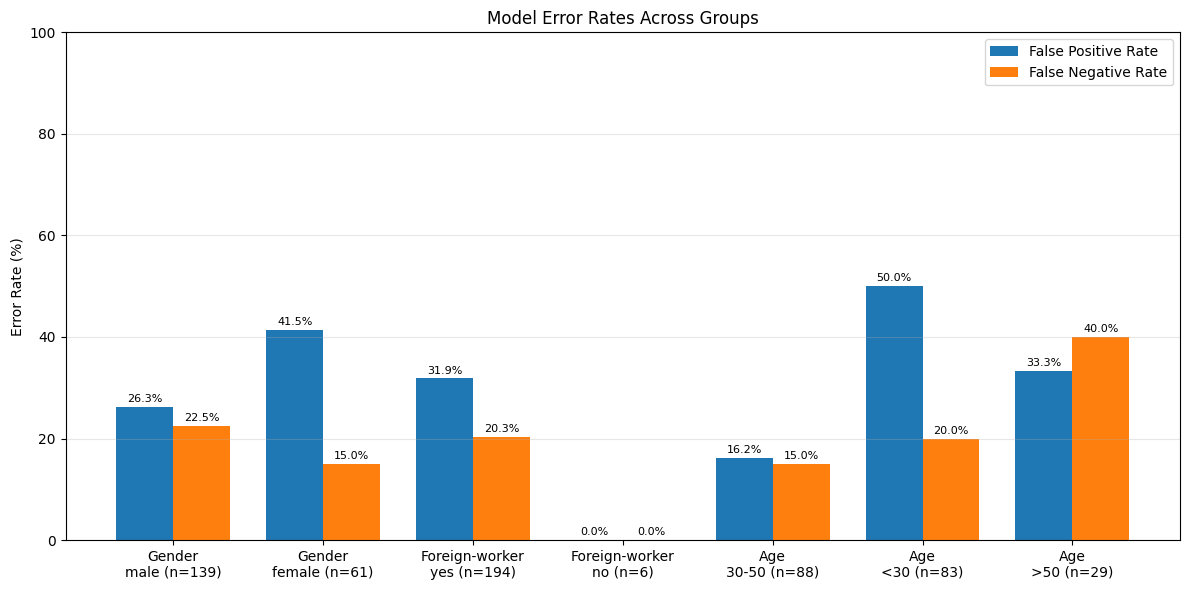

In [38]:
# Error rates by group

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Calculate error rates for every group
group_results = []

features = {
    "Gender": "sex",
    "Foreign-worker": "foreign_worker",
    "Age": "age_group"
}

for feature, column in features.items():
    for group in fairness_df[column].dropna().unique():
        data = fairness_df[fairness_df[column] == group]

        tn, fp, fn, tp = confusion_matrix(
            data["actual"],
            data["predicted"],
            labels=[0, 1]
        ).ravel()

        group_results.append({
            "Feature": feature,
            "Group": str(group),
            "N": len(data),
            "FPR": fp / (fp + tn) if (fp + tn) else 0,
            "FNR": fn / (fn + tp) if (fn + tp) else 0
        })

error_rates = pd.DataFrame(group_results)

# Plot both error rates
x = np.arange(len(error_rates))
width = 0.38

fig, ax = plt.subplots(figsize=(12, 6))

bars1 = ax.bar(x - width/2, error_rates["FPR"] * 100,
               width, label="False Positive Rate")

bars2 = ax.bar(x + width/2, error_rates["FNR"] * 100,
               width, label="False Negative Rate")

ax.set_title("Model Error Rates Across Groups")
ax.set_ylabel("Error Rate (%)")
ax.set_xticks(x)
ax.set_xticklabels([
    f"{row['Feature']}\n{row['Group']} (n={row['N']})"
    for _, row in error_rates.iterrows()
])
ax.legend()
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)

ax.bar_label(bars1, fmt="%.1f%%", padding=2, fontsize=8)
ax.bar_label(bars2, fmt="%.1f%%", padding=2, fontsize=8)

plt.tight_layout()
plt.show()

ROC-AUC 0.81


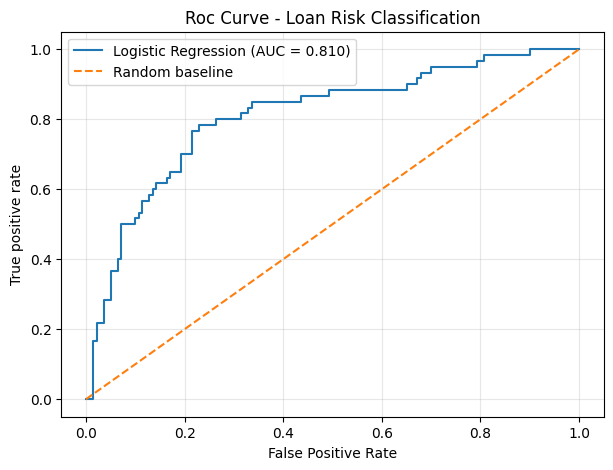

In [39]:
from sklearn.metrics import roc_auc_score, roc_curve, auc

# Get predicted probabilities for class 1(high credit risk)
risk_probabilities = best_log_reg.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
auc_score = roc_auc_score(y_test, risk_probabilities)
print("ROC-AUC", round(auc_score, 3))

# Calculate roc curve
fpr, tpr, thresholds = roc_curve(y_test, risk_probabilities)


# Plot the ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True positive rate")
plt.title("Roc Curve - Loan Risk Classification")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Observation
The tuned Logistic Regression model achieved an ROC-AUC score of 0.81, indicating good ability to distinguish between high-risk and low-risk applicants. The ROC curve illustrates the trade-off between the true positive rate and false positive rate across classification thresholds. 

However, the overall ROC-AUC score does not show whether prediction errors are distributed equally across demographic groups. Further analysis is needed to understand these differences and the potential consequences for loan approval decisions. 

### Error Rate Observations

- Gender: Female applicants had a higher FNR (80%) than male applicants (60%), meaning the model missed a larger proportion of high-risk female applicants.
- Foreign-worker status: Foreign-worker applicants had a 67.8% FNR. The non-foreign-worker group had 0% observed error rates, but contained only 6 applicants. 
- Age: Applicants under 30 had the highest FNR(74.3%) followed by those aged 30-50(60%) and over 50(40%).

The model misses a substantial proportion of high-risk applicants, particularly female applicants and those under 30. These disparities warrant further investigation, although small group sizes limit some comparisons.

Although the model demonstrates good overall discrimination, the group-level error rates reveal differences in how applicants may be classified. These findings raise questions about whether changing the classification threshold could alter the balance between financial risk and fairness across demographic groups. This motivates the next stage of threshold analysis.

## Threshold Analysis

The error analysis identified differences in false positive and false negative rates across demographic groups. However, these results the model's current classification threshold.

Threshold analysis examines how changing that threshold affects prediction error and fairness across groups. The goal is to understand the trade-offs before recommending whether the model is suitable for loan approcal decisions.


In [40]:
thresholds_to_test = [0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = []

for threshold in thresholds_to_test:
    threshold_pred = (risk_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, 
        threshold_pred, 
        labels = [0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "False Positives": fp,
        "False Negatives": fn,
        "FPR": fp/(fp + tn) if (fp + tn) else 0,
        "FNR": fn/(fn + tp) if (fn + tp) else 0,
        "Recall": tp/(tp + fn) if (tp + fn) else 0
    })

threshold_results_df = pd.DataFrame(threshold_results)
display(threshold_results_df.round(3))


,Threshold,False Positives,False Negatives,FPR,FNR,Recall
0,0.3,78,7,0.557,0.117,0.883
1,0.4,60,9,0.429,0.150,0.850
2,0.5,43,12,0.307,0.200,0.800
3,0.6,25,21,0.179,0.350,0.650
4,0.7,12,30,0.086,0.500,0.500


### Threshold analysis: Overall error trade-off

Increasing the classification threshold from 0.3 to 0.7 reduced false positives from 78 to 12, while false negatives increased from 7 to 30. The false positive rate decreased from 0.557 to 0.086, whereas the false negative rate increased from 0.117 to 0.500. 
This demonstrates a trade-off between incorrectly flagging low-risk applicants and failing to identify high-risk applicants. A higher threshold reduces false alarms but may expose the lender to greater financial risk by missing more high-risk applicants. 
However, overall results alone do not show whether these changes affect demographic groups differently.

In [41]:
threshold = 0.6

# Apply this threshold to the existing predicted probabilities
threshold_pred = (risk_probabilities >= threshold).astype(int)

# Copy existing fairness data and update predictions
threshold_df = fairness_df.copy()
threshold_df["predicted"] = threshold_pred

# Compare error rates by gender
gender_results = []

for group in threshold_df["sex"].dropna().unique():
    group_df = threshold_df[threshold_df["sex"] == group]

    tn, fp, fn, tp = confusion_matrix(
        group_df["actual"],
        group_df["predicted"],
        labels=[0, 1]
    ).ravel()

    gender_results.append({
        "Gender": group, 
        "N": len(group_df),
        "FPR": fp / (fp + tn) if (fp + tn) else 0,
        "FNR": fn / (fn + tp) if(fn + tp) else 0,
        "Recall": tp / (tp + fn) if (tp + fn) else 0
    })

gender_threshold_df = pd.DataFrame(gender_results)
display(gender_threshold_df.round(3))

,Gender,N,FPR,FNR,Recall
0,male,139,0.162,0.40,0.60
1,female,61,0.220,0.25,0.75


At a threshold of 0.6, female applicants had a higher FPR, while male applicants had a higher FNR. This suggests that the model's errors differ by gender. However, further comparison across thresholds is needed to understand how changing the threshold affects these disparities. 

In [42]:
thresholds_to_test = [0.3, 0.4, 0.5, 0.6, 0.7]
gender_results = []
for threshold in thresholds_to_test:
    threshold_pred = (risk_probabilities >= threshold).astype(int)

    threshold_df = fairness_df.copy()
    threshold_df["predicted"] = threshold_pred
    # Compare results by gender
    
    for group in threshold_df["sex"].dropna().unique():
        group_df = threshold_df[threshold_df["sex"] == group]

        tn, fp, fn, tp = confusion_matrix(
            group_df["actual"],
            group_df["predicted"],
            labels=[0, 1]
        ).ravel()

        gender_results.append({
            "Threshold": threshold,
            "Gender": group,
            "N": len(group_df),
            "FPR": fp / (fp + tn) if (fp + tn) else 0,
            "FNR": fn /(fn + tp) if (fn + tp) else 0,
            "Recall": tp / (tp + fn) if (tp + fn) else 0
            
        })

gender_threshold_df = pd.DataFrame(gender_results)
display(gender_threshold_df.round(3))

,Threshold,Gender,N,FPR,FNR,Recall
0,0.3,male,139,0.525,0.150,0.850
1,0.3,female,61,0.634,0.050,0.950
2,0.4,male,139,0.374,0.175,0.825
3,0.4,female,61,0.561,0.100,0.900
4,0.5,male,139,0.263,0.225,0.775
5,0.5,female,61,0.415,0.150,0.850
6,0.6,male,139,0.162,0.400,0.600
7,0.6,female,61,0.220,0.250,0.750
8,0.7,male,139,0.071,0.550,0.450
9,0.7,female,61,0.122,0.400,0.600


Female applicants had a higher FPR, while make applicants had a higher FNR across all thresholds. Increasing the threshold reduced false positives but increased false negatives for both groups. This shows that changing the threshold shifts the types of errors rather than eliminating gender disparities. 

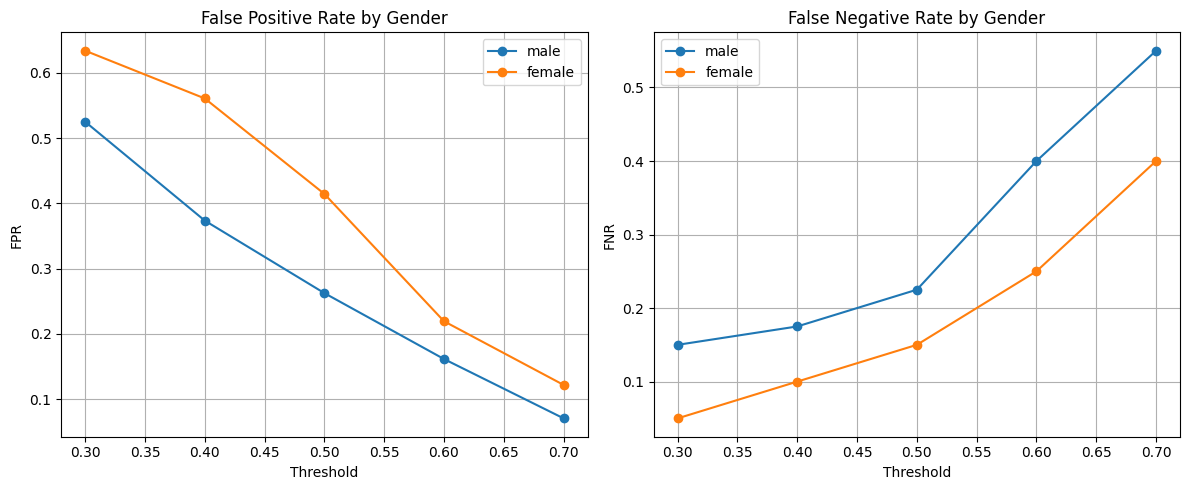

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for gender in ["male", "female"]:
    group = gender_threshold_df[
    gender_threshold_df["Gender"] == gender
    ].sort_values("Threshold")

    axes[0].plot(group["Threshold"], group["FPR"],
                marker="o", label=gender)
    axes[1].plot(group["Threshold"], group["FNR"], 
                marker="o", label=gender)


axes[0].set_title("False Positive Rate by Gender")
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("FPR")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("False Negative Rate by Gender")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("FNR")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


As the threshold increases, FPR decreases while FNR increases for both genders. Female applicants have higher FPR, while male applicants have a higher FNR across all tested thresholds. This shows a trade-off between two types of erros and differences in how they affect each group.

## SHAP Explainability

SHAP helps explain how individual features influence the model's predictions. In this project, it helps us understand which features push loan applicants toward a high-risk or low-risk prediction.

In [44]:
# Create a SHAP explainer
import shap

# Explain the tuned Logistic Regression model
explainer = shap.Explainer(best_log_reg, X_train)

# Calculate SHAP values for the test data
shap_values = explainer(X_test)

Background dataset has 800 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=800 when initializing the masker.


The SHAP summary plot shows which features have the greatest influence on model predictions and whether they push predictions toward high or low credit risk

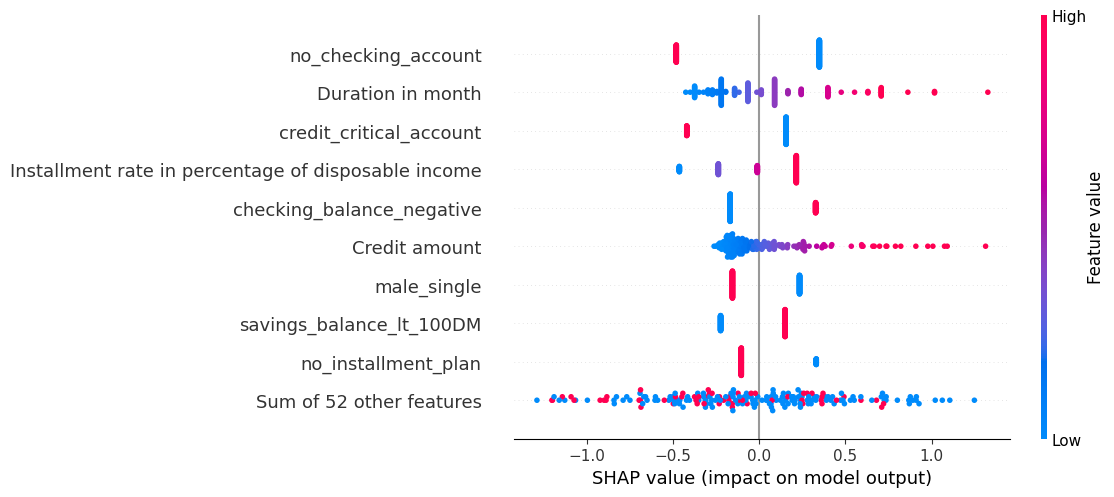

In [45]:
# Visualize feature impact across test applicants
shap.plots.beeswarm(shap_values)

### Observation:
Checking account status, loan duration, credit history, installment rate, and credit amount were among the most influential features. Longer loan durations and higher credit amounts generally pushed predictions toward high risk. However, SHAP explains model behaviour, not whether these features independently cause credit risk.

In [46]:
# Compare credit amount and loan duration by actual risk
analysis_df = X_test.copy()
analysis_df["actual_risk"] = y_test.values

analysis_df.groupby("actual_risk")[
["Credit amount", "Duration in month"]
].mean().rename(
    index={0: "Low risk", 1: "High risk"}
)

,Credit amount,Duration in month
actual_risk,,
Low risk,3139.885714,19.335714
High risk,4666.683333,26.333333


### Observation:
High-risk applicants had a higher higher average credit amount and longer loan duration. This supports the patterns observed in SHAP, although these differences do not prove that either feature cause credit risk.

## Permutation Importance

Permutation importance measures how much model performance decreases when a feature's values are randomly shuffled. A largeer decrease suggests the model relies more on that feature for its prediction.

In [47]:
from sklearn.inspection import permutation_importance
import pandas as pd

# Measure feature importance using the held-out test set
perm_result = permutation_importance(
    best_log_reg,
    X_test, 
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42
)

# Rank features by their average importance
importance_df = pd.DataFrame({
    "Feature": X_test.columns, 
    "Importance": perm_result.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df.head(10).round(4))

,Feature,Importance
10,no_checking_account,0.0632
15,credit_critical_account,0.0380
7,checking_balance_negative,0.0351
0,Duration in month,0.0213
16,purpose_car(new),0.0199
2,Installment rate in percentage of disposable i...,0.0153
17,purpose_car(old),0.0139
26,savings_balance_lt_100DM,0.0115
34,employment_duration_4_to_7yrs,0.0111
11,credit_all_paid,0.0090


Checking account status and foreign worker status

I examined the relationship between checking account status and foreign worker status to investigate whether the model's reliance on checking-account information could be associated with foreign-worker status.

In [48]:
comparison = pd.crosstab(
    final_df["Foreign worker_A201"],
    final_df["Status of existing checking account_A14"],
    rownames=["Foreign worker"],
    colnames=["No checking account"],
    normalize="index"
)

display(comparison.round(3))

No checking account,0.0,1.0
Foreign worker,,
0.0,0.649,0.351
1.0,0.604,0.396


### Observation

Foreign workers were slightly more likely to have no checking account than non-foreign workers. However, the 4.5 percentage-point difference is small and does not establish that checking-account status acts as a proxy for foreign-worker status.

,Checking status,FPR,FNR
0,Has checking account,0.529,0.135
1,No checking account,0.086,0.625


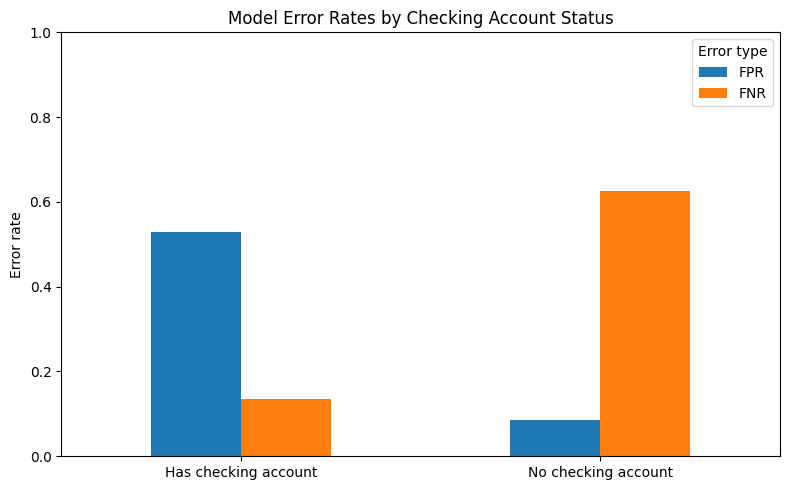

In [51]:
from sklearn.metrics import confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt

results = []

fairness_df["checking_status"] = np.where(
    fairness_df["no_checking_account"] == 1,
    "No checking account",
    "Has checking account"
)

for group, data in fairness_df.groupby("checking_status"):
    tn, fp, fn, tp = confusion_matrix(
        data["actual"], data["predicted"], labels=[0, 1]
    ).ravel()

    results.append({
        "Checking status": group,
        "FPR": fp / (fp + tn) if (fp + tn) else 0,
        "FNR": fn / (fn + tp) if (fn + tp) else 0
    })

error_df = pd.DataFrame(results)

# Display corrected rates
display(error_df.round(3))

# Plot comparison
error_df.set_index("Checking status")[["FPR", "FNR"]].plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Model Error Rates by Checking Account Status")
plt.ylabel("Error rate")
plt.xlabel("")
plt.legend(title="Error type")
plt.tight_layout()
plt.show()

### Observation: 

Applicants with checking accoutns had a higher false-positive rate, while applicants without checking accoutns had a higher false-negative rate. However, the latter rate is based on only eight high-risk applicants, so the result should be interpreted cautiously. This suggests differnt error patterns across checking-account groups but does not establish discrimination.

In [52]:
for group, data in fairness_df.groupby("checking_status"):
    tn, fp, fn, tp = confusion_matrix(
        data["actual"], data["predicted"], labels=[0, 1]
    ).ravel()

    print(f"\n{group}")
    print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")
    print(f"Actual low-risk: {tn + fp}")
    print(f"Actual high-risk: {fn + tp}")


Has checking account
TN: 33, FP: 37, FN: 7, TP: 45
Actual low-risk: 70
Actual high-risk: 52

No checking account
TN: 64, FP: 6, FN: 5, TP: 3
Actual low-risk: 70
Actual high-risk: 8


## Conclusion 

Logistic Regression achieved an F1 score of 0.658 and ROC-AUC of 0.81, identifying 48 out of 60 high-risk applicants. However, it also produced 43 false positives. Fairness analysis revealed differences in error rates across demographic and financial groups, while SHAP and permutation importance highlighted influential features such as checking-account status and credit history.

These results show that predictive performance alone is not enough to establish fairness or readiness for real-world lending decisions. 


## Recommendations

- **Delay deployment** until further validation is completed.
- Evaluate the model on larger, more representative data to improve the reliability of subgroup comparison.
- Select decisions thresholds based on the costs of false positives and false negatives.
- Investigate differences in group error rates before considering real-world use.